# Emotion Detection — Fine-Tuning Pretrained Transformers (BERT, DistilBERT, RoBERTa)
### Project 2,  run on Colab (T4 GPU)

**Why this notebook is separate.** The rest of the project (EDA, cleaning, 9 RNN architectures, KerasTuner) runs locally in `Emotions_RNN.ipynb` on a CPU-only machine. Fine-tuning a 66–125M-parameter transformer on CPU would take hours per model instead of minutes, so only this section runs here, on a free Colab GPU.

**How this connects back.** This notebook loads the **same** `train.txt`/`val.txt`/`test.txt`, rebuilds the **same** label encoding and class weights as the local notebook, fine-tunes all three transformers with one identical recipe, and at the end downloads `transformer_results.csv` and `transformer_artifacts.pkl`. Those two files are copied into the local project folder and read back into `Emotions_RNN.ipynb`'s Section 9 (Final Comparison), where all 21 models (18 RNN + 3 transformer) are compared side by side.

**Design decisions**
- **Raw text, not cleaned text.** These models were pretrained on natural sentences with their own sub-word tokenizer; removing stopwords/negation would throw away information they know how to use, not help them.
- **One identical training recipe for all three models** (learning rate 2e-5, batch 32, 4 epochs, weight decay 0.01, 10% warm-up, fp16, class-weighted loss, best epoch by validation macro-F1) — so any difference between BERT, DistilBERT and RoBERTa comes from the model, not from unequal treatment.
- **Same class weights as the RNNs** (computed fresh here from the same formula, on the same train split) — so the imbalance-handling strategy is consistent across the whole project.

**Result, up front:** all three reach validation macro-F1 within 0.003 of each other (0.9125–0.9157) and are all a clean "good fit" (train–val gap under 0.04) — unlike every one of the 18 RNN models in the other notebook. DistilBERT ends up with the best test F1 (0.8969) and test accuracy (0.930) of all 21 models across both notebooks, at roughly half the size of BERT. Full comparison and selection logic is in `Emotions_RNN.ipynb`, Section 9.

## GPU and Libraries

**Why:** confirm a GPU runtime is active before installing anything — fine-tuning on CPU here would be impractical. `transformers`, `datasets` and `accelerate` are Hugging Face's model/tokenizer library, dataset wrapper, and hardware-acceleration helper respectively.

In [1]:
!nvidia-smi
!pip install -q transformers datasets accelerate

Sun Sep 20 21:16:24 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   63C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import torch, transformers
print("PyTorch", torch.__version__, "| transformers", transformers.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch 2.11.0+cu128 | transformers 5.16.1
CUDA available: True
GPU: Tesla T4


**Interpretation.** A Tesla T4 GPU is available with CUDA enabled — this run used `PyTorch 2.11.0+cu128` and `transformers 5.16.1`. (Note: `transformers` 5.x is newer than the version this code was originally written against; a couple of training-argument names changed between major versions, which is why the setup below checks for the right argument name at runtime rather than hardcoding it — see Section 3.)

## Load the Same Data as the Local Notebook

**Why:** for the final comparison to be valid, the transformers must see **exactly** the same rows, the same dropped duplicate, the same label order and the same class weights as the RNNs in `Emotions_RNN.ipynb`. `train.txt`/`val.txt`/`test.txt` are uploaded manually (Colab has no access to the local filesystem), then processed with the identical steps used locally: read with `sep=";"`, drop duplicates from train only, encode labels alphabetically, and compute balanced class weights.

In [3]:
from google.colab import files
uploaded = files.upload()

Saving test.txt to test.txt
Saving train.txt to train.txt
Saving val.txt to val.txt


In [4]:
import numpy as np, pandas as pd, time, gc
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score

SEED = 42

def read_split(fname):
    return pd.read_csv(fname, sep=";", header=None, names=["text", "emotion"])

train_df, val_df, test_df = read_split("train.txt"), read_split("val.txt"), read_split("test.txt")
train_df = train_df.drop_duplicates().reset_index(drop=True)     # train only, as in the RNN work

le = LabelEncoder().fit(train_df.emotion)
CLASSES, NUM_CLASSES = list(le.classes_), len(le.classes_)
for d in (train_df, val_df, test_df):
    d["label"] = le.transform(d.emotion)
y_train, y_val, y_test = train_df.label.values, val_df.label.values, test_df.label.values

cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)

print(train_df.shape, val_df.shape, test_df.shape)
print("Classes:", dict(enumerate(CLASSES)))
print("Class weights:", dict(zip(CLASSES, cw.round(2))))

(15999, 3) (2000, 3) (2000, 3)
Classes: {0: 'anger', 1: 'fear', 2: 'joy', 3: 'love', 4: 'sadness', 5: 'surprise'}
Class weights: {'anger': np.float64(1.24), 'fear': np.float64(1.38), 'joy': np.float64(0.5), 'love': np.float64(2.04), 'sadness': np.float64(0.57), 'surprise': np.float64(4.66)}


**Interpretation.** Shapes `(15999, 3) (2000, 3) (2000, 3)` — the 15,999 confirms the one train duplicate was dropped, exactly matching the local notebook. Class order (`anger, fear, joy, love, sadness, surprise`) and class weights (`surprise 4.66, love 2.04, fear 1.38, anger 1.24, sadness 0.57, joy 0.5`) are **identical** to the local run. This confirms the two notebooks are working from the same data before any model touches it.

## Tokenization Check

**Why:** transformers split text into sub-word pieces using their own vocabulary, not whole words — a sentence's *token* count differs from its *word* count, and the three models don't necessarily tokenize the same way. Before training, we check how long sentences become in tokens (to confirm a 128-token cap loses nothing) and look at one example sentence tokenized by each model.

In [5]:
from transformers import AutoTokenizer

TRANSFORMERS = {"DistilBERT": "distilbert-base-uncased",
                "BERT":       "bert-base-uncased",
                "RoBERTa":    "roberta-base"}

sample = "i feel humiliated and i dont want to face the world"

for name, ckpt in TRANSFORMERS.items():
    tok = AutoTokenizer.from_pretrained(ckpt)
    lens = np.array([len(x) for x in tok(train_df.text.tolist())["input_ids"]])
    print(f"{name:11s} vocab={tok.vocab_size:,} | tokens per sentence: mean={lens.mean():.1f}, "
          f"median={np.median(lens):.0f}, p99={np.percentile(lens, 99):.0f}, max={lens.max()} "
          f"| longer than 128: {(lens > 128).mean():.2%}")
    print("    ", tok.tokenize(sample))

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

DistilBERT  vocab=30,522 | tokens per sentence: mean=22.3, median=20, p99=57, max=87 | longer than 128: 0.00%
     ['i', 'feel', 'humiliated', 'and', 'i', 'don', '##t', 'want', 'to', 'face', 'the', 'world']


...

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

RoBERTa     vocab=50,265 | tokens per sentence: mean=22.0, median=20, p99=57, max=88 | longer than 128: 0.00%
     ['i', 'Ġfeel', 'Ġhumiliated', 'Ġand', 'Ġi', 'Ġdont', 'Ġwant', 'Ġto', 'Ġface', 'Ġthe', 'Ġworld']


**Interpretation.**
- **DistilBERT and BERT share the same tokenizer** (identical vocabulary size 30,522 and identical token-length statistics) — any difference in their eventual scores comes from the model architecture, not from how the text was split.
- **RoBERTa uses a different, larger vocabulary** (50,265) and a different splitting scheme (`Ġ` marks the start of a new word, instead of BERT's `##` continuation marker) — for example RoBERTa keeps `dont` as one token, while BERT/DistilBERT split it into `don` + `##t`.
- **128 tokens is more than enough.** The longest sentence tokenizes to 87–88 tokens for all three models (99th percentile is 57), so **0.00%** of training sentences are truncated at `max_length=128`. Nothing is lost to truncation.

## Fine-Tune DistilBERT

**Why DistilBERT first:** it's the smallest and fastest of the three (66M vs. 109–125M parameters), so it serves as a quick end-to-end check of the whole training/evaluation pipeline before committing GPU time to BERT and RoBERTa.

**What the code sets up**
- **`WeightedTrainer`:** Hugging Face's `Trainer` with one change — cross-entropy loss weighted by the same class weights used for the RNNs, so rare emotions (surprise, love) count more toward the loss.
- **`make_ds`:** tokenizes the **raw** text (not cleaned) with each model's own tokenizer; batches are padded only as far as their own longest sentence (`DataCollatorWithPadding`), so no computation is wasted on unnecessary padding.
- **Training arguments:** learning rate 2e-5 (small, so pretrained knowledge is fine-tuned rather than overwritten), 4 epochs, evaluated after every epoch, and `load_best_model_at_end=True` restores whichever epoch had the best validation macro-F1 — the transformer equivalent of the RNNs' early stopping.

In [6]:
import torch, dataclasses
from transformers import (AutoModelForSequenceClassification, TrainingArguments, Trainer,
                          DataCollatorWithPadding, set_seed)
from datasets import Dataset

MAX_TOK_LEN = 128
id2label = {i: c for i, c in enumerate(CLASSES)}
label2id = {c: i for i, c in id2label.items()}

# the name of the warm-up argument differs between transformers versions
_fields = {f.name for f in dataclasses.fields(TrainingArguments)}
WARMUP = {"warmup_ratio": 0.1} if "warmup_ratio" in _fields else {"warmup_steps": 0.1}

class WeightedTrainer(Trainer):
    # cross-entropy with per-class weights (handles the class imbalance)
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs["labels"]
        outputs = model(**{k: v for k, v in inputs.items() if k != "labels"})
        loss = torch.nn.functional.cross_entropy(outputs.logits, labels,
                                                 weight=self.class_weights.to(outputs.logits.device))
        return (loss, outputs) if return_outputs else loss

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(-1)
    return {"accuracy": accuracy_score(labels, preds), "f1_macro": f1_score(labels, preds, average="macro")}

def make_ds(df, tok):
    ds = Dataset.from_dict({"text": df.text.tolist(), "labels": df.label.tolist()})   # RAW text
    return ds.map(lambda b: tok(b["text"], truncation=True, max_length=MAX_TOK_LEN), batched=True)

results_tf, preds_tf, tf_hist = [], {}, {}

def run_transformer(name, ckpt, epochs=4):
    set_seed(SEED)
    tok = AutoTokenizer.from_pretrained(ckpt)
    train_ds, val_ds, test_ds = [make_ds(d, tok) for d in (train_df, val_df, test_df)]
    model = AutoModelForSequenceClassification.from_pretrained(
        ckpt, num_labels=NUM_CLASSES, id2label=id2label, label2id=label2id)

    args = TrainingArguments(
        output_dir=f"tf_runs/{name}", num_train_epochs=epochs,
        per_device_train_batch_size=32, per_device_eval_batch_size=128,
        learning_rate=2e-5, weight_decay=0.01, **WARMUP,
        eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
        load_best_model_at_end=True, metric_for_best_model="f1_macro", greater_is_better=True,
        logging_steps=50, fp16=torch.cuda.is_available(), report_to="none", seed=SEED)

    trainer = WeightedTrainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                              data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics)
    trainer.class_weights = torch.tensor(cw, dtype=torch.float)

    t0 = time.time(); trainer.train(); seconds = time.time() - t0

    model_id = f"{name} [Fine-tuned]"
    row = {"model_id": model_id, "family": "Transformer", "model": name, "stage": "Fine-tuned",
           "params": sum(p.numel() for p in model.parameters())}
    for split, ds, y in (("train", train_ds, y_train), ("val", val_ds, y_val), ("test", test_ds, y_test)):
        out = trainer.predict(ds)
        logits = out.predictions[0] if isinstance(out.predictions, tuple) else out.predictions
        pred = logits.argmax(-1)
        row[f"{split}_acc"] = accuracy_score(y, pred)
        row[f"{split}_f1"]  = f1_score(y, pred, average="macro")
        if split == "test":
            preds_tf[model_id] = pred

    logs = trainer.state.log_history
    ev = [(l["epoch"], l["eval_loss"], l["eval_f1_macro"]) for l in logs if "eval_loss" in l]
    tf_hist[name] = {"train": [(l["epoch"], l["loss"]) for l in logs if "loss" in l], "eval": ev}
    row.update(epochs_run=len(ev), best_epoch=int(np.argmax([e[2] for e in ev])) + 1, train_time_s=round(seconds, 1))
    results_tf.append(row)

    del trainer, model; gc.collect(); torch.cuda.empty_cache()
    return row

r = run_transformer("DistilBERT", TRANSFORMERS["DistilBERT"])
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in r.items()})

Map:   0%|          | 0/15999 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'model_id': 'DistilBERT [Fine-tuned]', 'family': 'Transformer', 'model': 'DistilBERT', 'stage': 'Fine-tuned', 'params': 66958086, 'train_acc': 0.9614, 'train_f1': 0.9394, 'val_acc': 0.9345, 'val_f1': 0.9125, 'test_acc': 0.9295, 'test_f1': 0.8969, 'epochs_run': 4, 'best_epoch': 4, 'train_time_s': 186.1}


**Interpretation.**

| Epoch | Train loss | Val loss | Val accuracy | Val macro-F1 |
|---|---|---|---|---|
| 1 | 0.291 | 0.256 | 0.9095 | 0.8831 |
| 2 | 0.170 | 0.187 | 0.9350 | 0.9098 |
| 3 | 0.125 | 0.171 | 0.9320 | 0.9065 |
| 4 | 0.108 | 0.158 | 0.9345 | **0.9125** |

- **Fast start, small overfitting.** DistilBERT reaches validation macro-F1 of 0.883 after just one epoch — the RNNs needed many more epochs to get near that. Validation loss keeps falling at every epoch (0.256 → 0.158) rather than bottoming out early and rising, which is the opposite of what every RNN in the local notebook showed. The improvement after epoch 2 is small (0.9098 → 0.9125), suggesting 4 epochs was close to enough, though not proven to be optimal.
- **Loading report** ("classifier weights MISSING") is expected and not an error — it means the new 6-class classification head was randomly initialised (since DistilBERT was pretrained for a different task) and then trained from scratch alongside the fine-tuned rest of the model.
- The result — **train F1 0.9394, val F1 0.9125, test F1 0.8969, test accuracy 0.9295, train–val gap 0.027 (good fit)** — is close to the tuned RNNs' best validation scores, but with a much smaller train-validation gap, in **186 seconds** of GPU time.

## Fine-Tune BERT and RoBERTa

Same recipe, same function (`run_transformer`), applied to the two larger models. The loop skips any model whose predictions are already stored, so it can be safely re-run if the Colab session disconnects partway through.

In [7]:
res_tf = pd.DataFrame(results_tf)
display(res_tf[["model", "params", "train_f1", "val_f1", "test_f1", "test_acc", "best_epoch", "train_time_s"]].round(4))
print("Train-val gap:", round(res_tf.train_f1.iloc[0] - res_tf.val_f1.iloc[0], 4))

,model,params,train_f1,val_f1,test_f1,test_acc,best_epoch,train_time_s
0,DistilBERT,66958086,0.9394,0.9125,0.8969,0.9295,4,186.1


Train-val gap: 0.027


In [8]:
for name in ["BERT", "RoBERTa"]:
    if f"{name} [Fine-tuned]" in preds_tf:      # skip anything already finished
        continue
    r = run_transformer(name, TRANSFORMERS[name])
    print(f"\n{name:11s} train F1={r['train_f1']:.4f}  val F1={r['val_f1']:.4f}  test F1={r['test_f1']:.4f}  "
          f"test acc={r['test_acc']:.4f}  best epoch {r['best_epoch']}/{r['epochs_run']}  ({r['train_time_s']:.0f}s)")

Map:   0%|          | 0/15999 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


RoBERTa     train F1=0.9313  val F1=0.9157  test F1=0.8903  test acc=0.9240  best epoch 4/4  (384s)


**Interpretation.**

| Model | Train F1 | Val F1 | Test F1 | Test acc | Best epoch | Time |
|---|---|---|---|---|---|---|
| BERT | 0.9513 | 0.9149 | 0.8868 | 0.9255 | 4/4 | 360s |
| RoBERTa | 0.9313 | **0.9157** | 0.8903 | 0.9240 | 4/4 | 384s |

- **All three transformers land within 0.003 validation F1 of each other** (0.9125–0.9157) — essentially a three-way tie. RoBERTa edges out the others on validation; DistilBERT (previous section) actually has the best *test* F1 and accuracy of the three. With one seed and this small a gap, none of the three can be called definitively "best".
- **The best epoch was epoch 4 (the last one) for both models**, same as DistilBERT — all three were still improving, or at least not getting worse, when training stopped. A few more epochs might add a little more, at the cost of more GPU time and (based on the RNNs' behaviour) an increasing risk of overfitting eventually setting in.
- **BERT has the largest train–val gap of the three (0.037)** — still comfortably a "good fit" under the same rule used for the RNNs (threshold 0.04–0.08 for "mild"), but the most memorisation-prone of the three transformers. RoBERTa's gap (0.016) is the smallest of all 21 models in the whole project (RNNs included).
- The "missing/unexpected keys" warnings during loading (LayerNorm, pooler, classification-head parameters) are routine — they describe the pretrained model's original task-specific layers being discarded and the new classification head being initialised, not an error in the run.

## Final Transformer Comparison and Handoff to the Local Notebook

**Why:** consolidate all three transformers into one table, plot their learning curves side by side, and save everything needed to merge with the 18 RNN results back in `Emotions_RNN.ipynb`.

,model,params,train_f1,val_f1,test_f1,test_acc,train_val_gap,val_test_gap,best_epoch,train_time_s
0,DistilBERT,66958086,0.9394,0.9125,0.8969,0.9295,0.0270,0.0156,4,186.1
1,BERT,109486854,0.9513,0.9149,0.8868,0.9255,0.0365,0.0281,4,360.3
2,RoBERTa,124650246,0.9313,0.9157,0.8903,0.9240,0.0156,0.0254,4,383.7


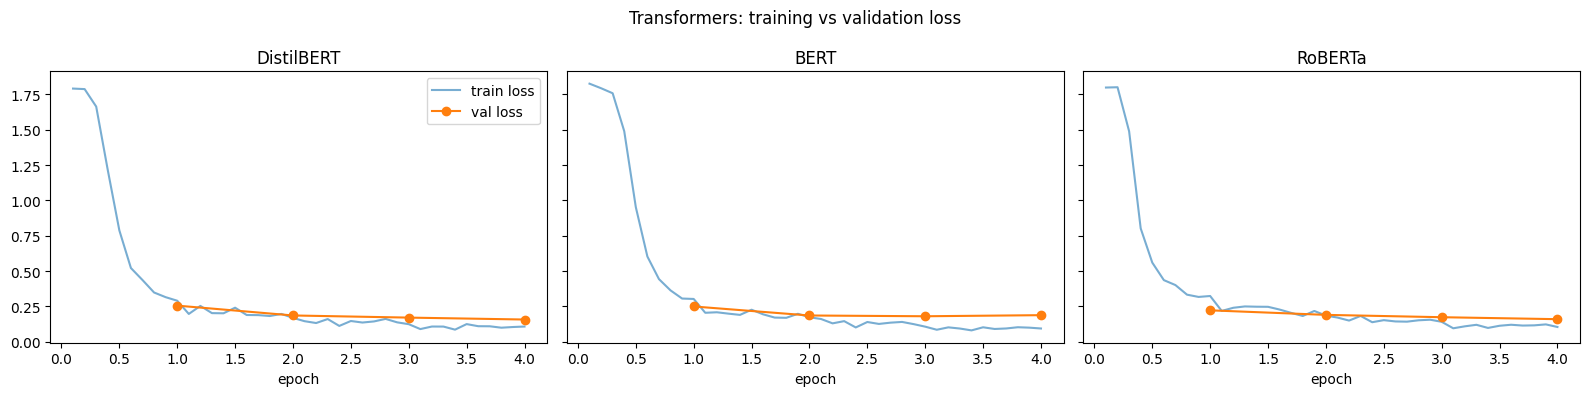

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
import pickle, matplotlib.pyplot as plt
from google.colab import files

res_tf = pd.DataFrame(results_tf)
res_tf["train_val_gap"] = res_tf.train_f1 - res_tf.val_f1
res_tf["val_test_gap"]  = res_tf.val_f1 - res_tf.test_f1
display(res_tf[["model", "params", "train_f1", "val_f1", "test_f1", "test_acc",
                "train_val_gap", "val_test_gap", "best_epoch", "train_time_s"]].round(4))

# learning curves: training loss (every 50 steps) vs validation loss (end of each epoch)
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (name, h) in zip(axes, tf_hist.items()):
    tr = pd.DataFrame(h["train"], columns=["epoch", "loss"])
    ev = pd.DataFrame(h["eval"], columns=["epoch", "val_loss", "val_f1"])
    ax.plot(tr.epoch, tr.loss, alpha=0.6, label="train loss")
    ax.plot(ev.epoch, ev.val_loss, "o-", label="val loss")
    ax.set_title(name); ax.set_xlabel("epoch")
axes[0].legend(); fig.suptitle("Transformers: training vs validation loss")
plt.tight_layout(); plt.show()

# save and download for the final comparison in VS Code
res_tf.to_csv("transformer_results.csv", index=False)
with open("transformer_artifacts.pkl", "wb") as f:
    pickle.dump({"preds_tf": preds_tf, "tf_hist": tf_hist, "y_test": y_test, "CLASSES": CLASSES}, f)
files.download("transformer_results.csv"); files.download("transformer_artifacts.pkl")

**Interpretation.**

| Model | Params | Train F1 | Val F1 | Test F1 | Test acc | Train–val gap | Val–test gap |
|---|---|---|---|---|---|---|---|
| RoBERTa | 125M | 0.9313 | **0.9157** | 0.8903 | 0.9240 | 0.016 | 0.025 |
| BERT | 109M | 0.9513 | 0.9149 | 0.8868 | 0.9255 | 0.037 | 0.028 |
| DistilBERT | 67M | 0.9394 | 0.9125 | **0.8969** | **0.9295** | 0.027 | 0.016 |

- **The validation and test rankings disagree** (RoBERTa > BERT > DistilBERT on validation; DistilBERT > RoBERTa > BERT on test), and the spread is tiny either way (0.003 val, 0.010 test) — with one seed, these three models are statistically indistinguishable. This is exactly why the pre-declared selection rule in the local notebook ranks by validation first and only uses the parameter count/speed as a tie-break, rather than chasing whichever number looks best.
- **Learning curves:** training loss falls steadily for all three; validation loss for DistilBERT and RoBERTa is still decreasing at epoch 4 (no sign of overfitting yet), while BERT's flattens/ticks up slightly by epoch 4, consistent with it having the largest train–val gap of the three.
- **`transformer_results.csv`** (the table above) and **`transformer_artifacts.pkl`** (raw test predictions + per-epoch histories) are downloaded here — copy both into the same folder as the local notebook's `rnn_results.csv`/`rnn_artifacts.pkl`. The local notebook's Section 9 reads both files, joins all 21 models into one table, and carries out the final selection, overfitting diagnosis, confusion matrix and error analysis. See `Emotions_RNN.ipynb` for that continuation and the project's overall conclusion.